# Machine Learning – Milestone 2: Model Implementation & Evaluation

**Problem:** predicting 30-day hospital readmission of diabetic patients (binary classification, positive class = readmitted within 30 days)
**Dataset:** *Diabetes 130-US Hospitals for Years 1999–2008* (UCI, ID 296), the same personalised subsample as Milestone 1
**Student ID:** SH2301468  |  **Seed:** `SEED = 2301468`  |  **Milestone 1 repository:** https://github.com/sherry2301468/ML-Milestone1

**What this notebook does (Milestone 2 tasks):**
1. Train several supervised models (logistic regression, decision tree, random forest, gradient boosting) against a do-nothing baseline.
2. Use an **unsupervised method (k-means clustering)** to engineer new features, and test honestly whether they help.
3. Evaluate with **patient-grouped cross-validation**, confusion matrices and metrics (accuracy, precision, recall, F1, ROC-AUC, PR-AUC, probability RMSE).
4. Tune hyperparameters with **randomised search**, choose a decision threshold, and report final results on the untouched test set.

All numbers come from the personalised subsample, never from the full public file.

## 1. Setup and reproducing the Milestone 1 data
*Analogy:* Milestone 1 was preparing the ingredients. Here we first re-prepare exactly the same ingredients (same seed, same steps), then check
a "fingerprint" to prove the portions are identical, before we start cooking (training models).

`QUICK_RUN` is a switch for fast test runs. It must be `False` (the default) for the real results in this notebook.

In [1]:
import os, hashlib, platform, tempfile, warnings, time
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import joblib
import sklearn
from IPython.display import display
from scipy.stats import loguniform, randint
from sklearn.base import BaseEstimator, TransformerMixin, clone
from sklearn.cluster import KMeans
from sklearn.compose import ColumnTransformer
from sklearn.decomposition import PCA
from sklearn.dummy import DummyClassifier
from sklearn.ensemble import HistGradientBoostingClassifier, RandomForestClassifier
from sklearn.inspection import permutation_importance
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import (accuracy_score, average_precision_score, balanced_accuracy_score, ConfusionMatrixDisplay,
                             f1_score, precision_recall_curve, precision_score, recall_score, roc_auc_score,
                             roc_curve, silhouette_score)
from sklearn.model_selection import RandomizedSearchCV, StratifiedGroupKFold, train_test_split
from sklearn.pipeline import FeatureUnion, Pipeline
from sklearn.preprocessing import FunctionTransformer, OneHotEncoder, StandardScaler
from sklearn.tree import DecisionTreeClassifier

warnings.filterwarnings("ignore")
sns.set_theme(style="whitegrid")
pd.set_option("display.max_columns", 40)
pd.set_option("display.width", 150)

STUDENT_ID = "SH2301468"
SEED = int("".join(ch for ch in STUDENT_ID if ch.isdigit()))          # 2301468
DATA_PATH = "diabetic_data.csv"
QUICK_RUN = os.environ.get("QUICK_RUN", "0") == "1"                  # False for the real run
np.random.seed(SEED)

# Run-size settings (smaller only when QUICK_RUN is on)
CV_FOLDS      = 3 if QUICK_RUN else 5      # folds for model comparison
SEARCH_FOLDS  = 2 if QUICK_RUN else 3      # folds inside hyper-parameter search
N_ITER        = dict(zip(["Logistic Regression", "Decision Tree", "Random Forest", "Gradient Boosting (HGB)"],
                         [2, 2, 2, 2] if QUICK_RUN else [6, 10, 5, 10]))
RF_TREES      = 20 if QUICK_RUN else 100
N_BOOT        = 20 if QUICK_RUN else 300
PERM_ROWS     = 500 if QUICK_RUN else 4000
PERM_REPEATS  = 2 if QUICK_RUN else 5
SIL_ROWS      = 1500 if QUICK_RUN else 6000

MEMORY = joblib.Memory(location=tempfile.mkdtemp(prefix="m2cache_"), verbose=0)   # speeds up repeated preprocessing

print("Student ID:", STUDENT_ID, "| SEED:", SEED, "| QUICK_RUN:", QUICK_RUN)
print("Python", platform.python_version(), "| numpy", np.__version__, "| pandas", pd.__version__, "| scikit-learn", sklearn.__version__)

Student ID: SH2301468 | SEED: 2301468 | QUICK_RUN: False
Python 3.12.3 | numpy 2.5.4 | pandas 3.0.6 | scikit-learn 1.9.1


In [2]:
# ---- Milestone 1 data, rebuilt with exactly the same steps and seed ----
raw = pd.read_csv(DATA_PATH, keep_default_na=False, na_values=["?"], low_memory=False)   # keep "None" = test not performed
assert raw.shape == (101766, 50), raw.shape
raw["y_30"] = (raw["readmitted"] == "<30").astype(int)

patients = (raw.groupby("patient_nbr", as_index=False)["y_30"].max()
               .rename(columns={"y_30": "ever_readmitted_30"})
               .sort_values("patient_nbr").reset_index(drop=True))
kept_ids, _ = train_test_split(patients["patient_nbr"], train_size=0.80, stratify=patients["ever_readmitted_30"],
                               random_state=SEED, shuffle=True)
kept_ids = set(kept_ids.tolist())
df = raw[raw["patient_nbr"].isin(kept_ids)].drop(columns="y_30").reset_index(drop=True)
df["target"] = (df["readmitted"] == "<30").astype(int)

fingerprint = hashlib.sha256(",".join(map(str, sorted(kept_ids))).encode()).hexdigest()
print("Subsample fingerprint:", fingerprint)
assert fingerprint.startswith("159456edbd79"), "Subsample differs from Milestone 1: check the data file and seed"
print(f"Patients kept: {len(kept_ids):,} | encounters: {len(df):,} | matches Milestone 1")

Subsample fingerprint: 159456edbd794ca8a1d9da41a56d7e0e2926edde0153f4225d3d5291ce05eea2
Patients kept: 57,214 | encounters: 81,278 | matches Milestone 1


In [3]:
# ---- Milestone 1 cleaning (identical logic) ----
DRUG_COLS = ["metformin", "repaglinide", "nateglinide", "chlorpropamide", "glimepiride", "acetohexamide",
             "glipizide", "glyburide", "tolbutamide", "pioglitazone", "rosiglitazone", "acarbose", "miglitol",
             "troglitazone", "tolazamide", "examide", "citoglipton", "insulin", "glyburide-metformin",
             "glipizide-metformin", "glimepiride-pioglitazone", "metformin-rosiglitazone", "metformin-pioglitazone"]
AGE_MIDPOINT = {f"[{a}-{a + 10})": a + 5 for a in range(0, 100, 10)}
DEAD_OR_HOSPICE = [11, 13, 14, 19, 20, 21]
ID_AS_CATEGORY = ["admission_type_id", "discharge_disposition_id", "admission_source_id"]


def icd9_group(code):
    """Group an ICD-9 code into the 9 clinical categories of Strack et al. (2014)."""
    if pd.isna(code):
        return "Missing"
    c = str(code)
    if c.startswith(("V", "E")):
        return "Other"
    i = int(float(c))
    if i == 250:                              return "Diabetes"
    if 390 <= i <= 459 or i == 785:           return "Circulatory"
    if 460 <= i <= 519 or i == 786:           return "Respiratory"
    if 520 <= i <= 579 or i == 787:           return "Digestive"
    if 580 <= i <= 629 or i == 788:           return "Genitourinary"
    if 710 <= i <= 739:                       return "Musculoskeletal"
    if 800 <= i <= 999:                       return "Injury"
    if 140 <= i <= 239:                       return "Neoplasms"
    return "Other"


def clean(frame):
    d = frame[frame["gender"] != "Unknown/Invalid"]
    d = d[~d["discharge_disposition_id"].isin(DEAD_OR_HOSPICE)]
    d = d.drop(columns=["encounter_id", "weight", "readmitted"])
    near_constant = [c for c in DRUG_COLS if (d[c] == "No").mean() >= 0.995]
    d = d.drop(columns=near_constant).copy()
    d["age_num"] = d["age"].map(AGE_MIDPOINT)
    d = d.drop(columns="age")
    for k in (1, 2, 3):
        d[f"diag_{k}_group"] = d[f"diag_{k}"].map(icd9_group)
    d = d.drop(columns=["diag_1", "diag_2", "diag_3"])
    for col in ID_AS_CATEGORY:
        d[col] = d[col].astype(str)
    for col in ["race", "payer_code", "medical_specialty"]:
        d[col] = d[col].fillna("Missing")
    return d.reset_index(drop=True)


clean_df = clean(df)
y = clean_df["target"]
groups = clean_df["patient_nbr"]
X = clean_df.drop(columns=["target", "patient_nbr"])

NUM_STD  = ["time_in_hospital", "num_lab_procedures", "num_procedures", "num_medications", "number_diagnoses", "age_num"]
NUM_SKEW = ["number_outpatient", "number_emergency", "number_inpatient"]
CAT      = [c for c in X.columns if c not in NUM_STD + NUM_SKEW]

# Same group-aware, stratified 80/20 split as Milestone 1
sgkf = StratifiedGroupKFold(n_splits=5, shuffle=True, random_state=SEED)
train_idx, test_idx = next(sgkf.split(X, y, groups))
X_train, X_test = X.iloc[train_idx].reset_index(drop=True), X.iloc[test_idx].reset_index(drop=True)
y_train, y_test = y.iloc[train_idx].reset_index(drop=True), y.iloc[test_idx].reset_index(drop=True)
groups_train, groups_test = groups.iloc[train_idx].reset_index(drop=True), groups.iloc[test_idx].reset_index(drop=True)

if not QUICK_RUN:
    assert (len(X_train), len(X_test)) == (63490, 15875), (len(X_train), len(X_test))   # same sizes as Milestone 1
else:   # tiny sample only for a fast test run
    rs = np.random.RandomState(SEED)
    tr_ix, te_ix = rs.choice(len(X_train), 5000, replace=False), rs.choice(len(X_test), 1500, replace=False)
    X_train, y_train, groups_train = X_train.iloc[tr_ix].reset_index(drop=True), y_train.iloc[tr_ix].reset_index(drop=True), groups_train.iloc[tr_ix].reset_index(drop=True)
    X_test, y_test, groups_test = X_test.iloc[te_ix].reset_index(drop=True), y_test.iloc[te_ix].reset_index(drop=True), groups_test.iloc[te_ix].reset_index(drop=True)

assert set(groups_train).isdisjoint(set(groups_test))
print(f"Train: {len(X_train):,} encounters / {groups_train.nunique():,} patients | positive rate {y_train.mean():.2%}")
print(f"Test : {len(X_test):,} encounters / {groups_test.nunique():,} patients | positive rate {y_test.mean():.2%}")
print(f"Features before encoding: {X.shape[1]}  (identical to Milestone 1: sizes 63,490 / 15,875)")

Train: 63,490 encounters / 44,869 patients | positive rate 11.35%
Test : 15,875 encounters / 11,148 patients | positive rate 11.36%
Features before encoding: 33  (identical to Milestone 1: sizes 63,490 / 15,875)


In [4]:
# ---- Milestone 1 preprocessing building blocks (identical) ----
class Winsorizer(BaseEstimator, TransformerMixin):
    """Clip each column to [lower, upper] quantiles learned in fit() (tames outliers without deleting rows)."""
    def __init__(self, lower=0.01, upper=0.99):
        self.lower, self.upper = lower, upper

    def fit(self, X, y=None):
        X = np.asarray(X, dtype=float)
        self.lo_, self.hi_ = np.quantile(X, self.lower, axis=0), np.quantile(X, self.upper, axis=0)
        return self

    def transform(self, X):
        return np.clip(np.asarray(X, dtype=float), self.lo_, self.hi_)

    def get_feature_names_out(self, input_features=None):
        return np.asarray(input_features, dtype=object)


preprocessor = ColumnTransformer([
    ("num",  Pipeline([("winsor", Winsorizer()), ("scale", StandardScaler())]), NUM_STD),
    ("skew", Pipeline([("winsor", Winsorizer()), ("log1p", FunctionTransformer(np.log1p, feature_names_out="one-to-one")),
                       ("scale", StandardScaler())]), NUM_SKEW),
    ("cat",  OneHotEncoder(handle_unknown="infrequent_if_exist", min_frequency=0.01, sparse_output=False), CAT),
], verbose_feature_names_out=False)

print("Preprocessor defined. It will be re-fitted INSIDE every cross-validation fold (no leakage).")

Preprocessor defined. It will be re-fitted INSIDE every cross-validation fold (no leakage).


## 2. Evaluation framework
**Why not just accuracy?** Only about 11 % of encounters are 30-day readmissions. Predicting "no readmission" for everybody gives about 89 % accuracy
and finds nobody. So we report a family of metrics:

| Metric | What it answers |
|---|---|
| Accuracy | share of all predictions that are right (misleading under imbalance) |
| Precision | of the patients flagged, how many really returned |
| Recall | of the patients who returned, how many we caught |
| F1 | single number balancing precision and recall |
| ROC-AUC | how well the model ranks patients overall (threshold-free) |
| **PR-AUC** (average precision) | ranking quality focused on the rare positive class; **our main model-selection metric** |
| Probability RMSE | root-mean-square error of the predicted probabilities against 0/1 outcomes (the RMSE of the brief, adapted to classification) |

**Cross-validation design.** `StratifiedGroupKFold` splits by *patient* (no patient on both sides of any split) and keeps the class ratio in each fold.
Every model sees exactly the same folds, so comparisons are fair. The whole preprocessing pipeline is re-fitted inside each fold, so the validation
fold never influences scaling, clipping limits or category lists.

**Analogy:** cross-validation is like giving a student five different mock exams, each made from questions they have not studied, instead of judging them on one lucky paper.

In [5]:
def metrics_at(y_true, proba, thr=0.5):
    """All reported metrics for predicted probabilities `proba` at decision threshold `thr`."""
    y_true = np.asarray(y_true)
    pred = (proba >= thr).astype(int)
    return {"accuracy": accuracy_score(y_true, pred),
            "balanced_acc": balanced_accuracy_score(y_true, pred),
            "precision": precision_score(y_true, pred, zero_division=0),
            "recall": recall_score(y_true, pred, zero_division=0),
            "f1": f1_score(y_true, pred, zero_division=0),
            "roc_auc": roc_auc_score(y_true, proba),
            "pr_auc": average_precision_score(y_true, proba),
            "rmse_prob": float(np.sqrt(np.mean((proba - y_true) ** 2)))}


# The SAME folds are reused for every model
cv_folds = list(StratifiedGroupKFold(n_splits=CV_FOLDS, shuffle=True, random_state=SEED).split(X_train, y_train, groups_train))
print("Fold sizes (validation rows) and positive rates:")
for k, (tr, va) in enumerate(cv_folds, 1):
    print(f"  fold {k}: train {len(tr):,} | validation {len(va):,} | positive rate {y_train.iloc[va].mean():.2%} "
          f"| patient overlap {len(set(groups_train.iloc[tr]) & set(groups_train.iloc[va]))}")


def cv_eval(pipe, label=""):
    """Fit a fresh copy of `pipe` on each training fold; return out-of-fold probabilities and per-fold metrics."""
    t0 = time.time()
    oof, rows = np.zeros(len(y_train)), []
    for tr, va in cv_folds:
        m = clone(pipe).fit(X_train.iloc[tr], y_train.iloc[tr])
        p = m.predict_proba(X_train.iloc[va])[:, 1]
        oof[va] = p
        rows.append(metrics_at(y_train.iloc[va].values, p, 0.5))
    print(f"   {label:38s} done in {time.time() - t0:5.0f}s", flush=True)
    return oof, pd.DataFrame(rows)


def summarise(fold_df, cols=("accuracy", "precision", "recall", "f1", "roc_auc", "pr_auc", "rmse_prob")):
    return {c: f"{fold_df[c].mean():.3f} ± {fold_df[c].std():.3f}" for c in cols}

Fold sizes (validation rows) and positive rates:
  fold 1: train 50,793 | validation 12,697 | positive rate 11.36% | patient overlap 0
  fold 2: train 50,792 | validation 12,698 | positive rate 11.35% | patient overlap 0
  fold 3: train 50,793 | validation 12,697 | positive rate 11.35% | patient overlap 0
  fold 4: train 50,792 | validation 12,698 | positive rate 11.36% | patient overlap 0
  fold 5: train 50,790 | validation 12,700 | positive rate 11.36% | patient overlap 0


## 3. Baseline: the model that always says "no"
Before any real model, we need something to beat. `DummyClassifier(strategy="prior")` always outputs the overall readmission rate, so it never flags anyone.

In [6]:
dummy_oof, dummy_cv = cv_eval(DummyClassifier(strategy="prior"), "Dummy (always 'no readmission')")
print(pd.DataFrame([summarise(dummy_cv)], index=["Dummy baseline"]).to_string())

   Dummy (always 'no readmission')        done in     0s


                     accuracy      precision         recall             f1        roc_auc         pr_auc      rmse_prob
Dummy baseline  0.886 ± 0.000  0.000 ± 0.000  0.000 ± 0.000  0.000 ± 0.000  0.500 ± 0.000  0.114 ± 0.000  0.317 ± 0.000


**Finding.** The do-nothing model reaches 88.6 % accuracy yet catches 0 % of readmissions (recall 0.000). Its PR-AUC of 0.114 simply equals the share of positives, and its ROC-AUC of 0.500 is chance level. These are the numbers every real model must beat; accuracy would be a poor yardstick here.

## 4. Unsupervised learning: k-means clusters as engineered features
The brief asks for an unsupervised method used "for feature engineering". We use **k-means clustering**: it groups patients with similar profiles *without ever seeing the
readmission label*. The distance from each patient to each cluster centre then becomes a set of new numeric features ("how typical is this patient of group 1, 2, 3...?").

*Analogy:* sorting a crowd of patients into a few "types" by how alike they look, then telling the model how close each person is to each type.

**Leakage rule:** inside cross-validation the clustering is re-fitted on each training fold only (Section 5). Here we explore on the training set only, never the test set.

### 4.1 Choosing the number of clusters k
Two standard diagnostics: the **elbow** (inertia, the within-cluster spread, always falls as k grows, so we look for the bend) and the **silhouette score**
(how well-separated the clusters are; higher is better, 1 is perfect). We search k = 2..8 and pick the best silhouette among k >= 3 (a two-way split is too coarse to be useful as segmentation).

Preprocessed training matrix: (63490, 132)


  k=2: inertia=1,097,801  silhouette=0.078


  k=3: inertia=1,043,094  silhouette=0.077


  k=4: inertia=997,909  silhouette=0.060


  k=5: inertia=970,164  silhouette=0.057


  k=6: inertia=937,767  silhouette=0.058


  k=7: inertia=919,336  silhouette=0.048


  k=8: inertia=904,056  silhouette=0.045



Chosen k (best silhouette among k >= 3): 3


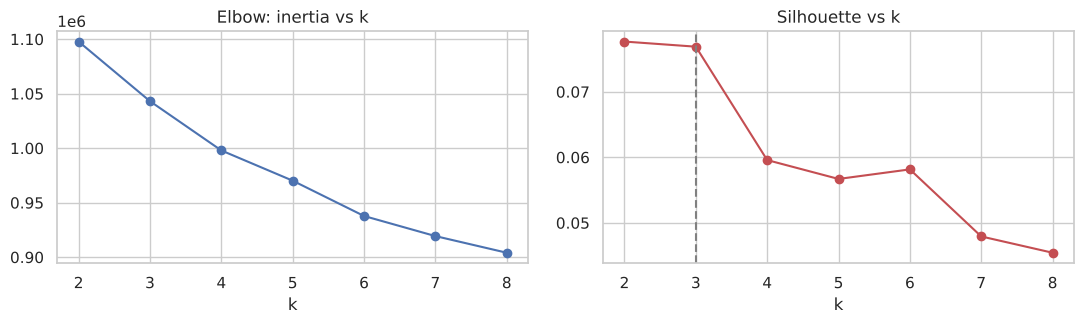

In [7]:
prep_explore = clone(preprocessor).fit(X_train)            # training data only
Xp = prep_explore.transform(X_train)
print("Preprocessed training matrix:", Xp.shape)

rng = np.random.RandomState(SEED)
sil_idx = rng.choice(len(Xp), size=min(SIL_ROWS, len(Xp)), replace=False)

rows = []
for k in range(2, 9):
    km = KMeans(n_clusters=k, n_init=3, random_state=SEED).fit(Xp)
    rows.append({"k": k, "inertia": km.inertia_, "silhouette": silhouette_score(Xp[sil_idx], km.labels_[sil_idx])})
    print(f"  k={k}: inertia={km.inertia_:,.0f}  silhouette={rows[-1]['silhouette']:.3f}", flush=True)
sweep = pd.DataFrame(rows)

K_CLUSTERS = int(sweep[sweep["k"] >= 3].sort_values("silhouette").iloc[-1]["k"])
print("\nChosen k (best silhouette among k >= 3):", K_CLUSTERS)

fig, ax = plt.subplots(1, 2, figsize=(11, 3.4))
ax[0].plot(sweep["k"], sweep["inertia"], marker="o"); ax[0].set_title("Elbow: inertia vs k"); ax[0].set_xlabel("k")
ax[1].plot(sweep["k"], sweep["silhouette"], marker="o", color="#C44E52"); ax[1].axvline(K_CLUSTERS, ls="--", color="grey")
ax[1].set_title("Silhouette vs k"); ax[1].set_xlabel("k")
plt.tight_layout(); plt.show()

### 4.2 What do the clusters look like? (profiles and 2-D picture)
We describe each cluster with a few real-world columns and, **only as an interpretation step**, look at how often its members were readmitted. The label was not used to build the clusters.
PCA squeezes the many columns onto two axes so that the clusters can be drawn.

,patients_rows,share,readmit_rate,mean_age,mean_days,mean_meds,prior_inpatient,diagnoses
cluster,,,,,,,,
0,34994,0.551,0.092,64.034,2.909,12.017,0.390,6.702
1,21894,0.345,0.131,69.473,6.813,22.271,0.722,8.349
2,6602,0.104,0.169,63.252,4.169,16.202,1.558,7.936


Variance explained by the first 2 principal components: [0.116 0.081] | total 0.197


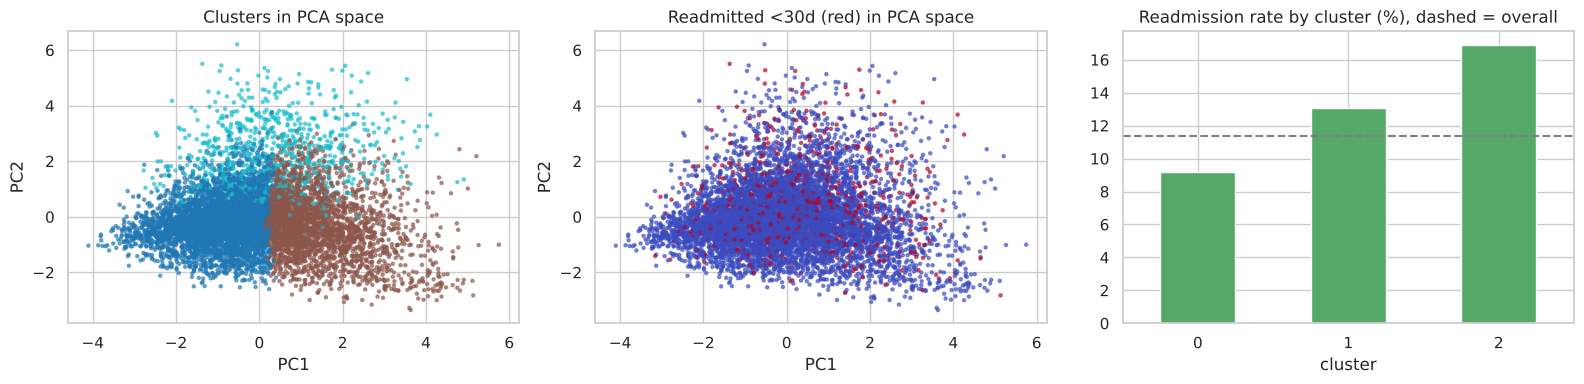

In [8]:
km_final = KMeans(n_clusters=K_CLUSTERS, n_init=10, random_state=SEED).fit(Xp)
labels = km_final.labels_

profile = (X_train.assign(cluster=labels, target=y_train.values)
           .groupby("cluster").agg(patients_rows=("target", "size"), readmit_rate=("target", "mean"),
                                   mean_age=("age_num", "mean"), mean_days=("time_in_hospital", "mean"),
                                   mean_meds=("num_medications", "mean"), prior_inpatient=("number_inpatient", "mean"),
                                   diagnoses=("number_diagnoses", "mean")).round(3))
profile.insert(1, "share", (profile["patients_rows"] / len(X_train)).round(3))
display(profile)

pca = PCA(n_components=2, random_state=SEED).fit(Xp)
pc_idx = rng.choice(len(Xp), size=min(8000, len(Xp)), replace=False)
Z = pca.transform(Xp[pc_idx])
print("Variance explained by the first 2 principal components:", np.round(pca.explained_variance_ratio_, 3),
      "| total", round(float(pca.explained_variance_ratio_.sum()), 3))

fig, ax = plt.subplots(1, 3, figsize=(16, 4))
sc = ax[0].scatter(Z[:, 0], Z[:, 1], c=labels[pc_idx], cmap="tab10", s=5, alpha=.6); ax[0].set_title("Clusters in PCA space")
ax[1].scatter(Z[:, 0], Z[:, 1], c=y_train.values[pc_idx], cmap="coolwarm", s=5, alpha=.6); ax[1].set_title("Readmitted <30d (red) in PCA space")
profile["readmit_rate"].mul(100).plot.bar(ax=ax[2], color="#55A868", rot=0)
ax[2].axhline(y_train.mean() * 100, ls="--", color="grey"); ax[2].set_title("Readmission rate by cluster (%), dashed = overall")
for a in ax[:2]:
    a.set_xlabel("PC1"); a.set_ylabel("PC2")
plt.tight_layout(); plt.show()

**Findings.**
* **The patients do not form sharply separated groups.** Silhouette scores are low for every k (0.045 to 0.078), and the first two principal components capture only 19.7 % of the variance. k = 2 scored marginally highest (0.078), but k = 3 (0.077) was chosen under the stated rule (k >= 3).
* **Even so, the three clusters are clinically sensible and differ in risk, although the readmission label was never used to build them:**
  * Cluster 0 (55 % of rows): short stays (2.9 days), about 12 medications, few earlier inpatient visits, **9.2 %** readmitted: the lowest risk.
  * Cluster 1 (35 %): older (mean age 69), longest stays (6.8 days), about 22 medications, 8.3 diagnoses, **13.1 %** readmitted.
  * Cluster 2 (10 %): the most earlier inpatient visits (1.56 on average), **16.9 %** readmitted: nearly double the risk of cluster 0.
* **Limitation.** Straight-line (Euclidean) distance on a mix of numeric and one-hot columns is only a rough notion of similarity; k-prototypes would be a method designed for mixed data.

## 5. Supervised models: default settings, with and without the cluster features
Four model families of increasing flexibility. *Analogy:* a linear model is a single ruler, a decision tree is a flow-chart of yes/no questions, a random forest is a committee of flow-charts voting,
and gradient boosting is a team where each new member specialises in the previous members' mistakes.

* **Logistic regression** – linear, easy to interpret, fast.
* **Decision tree** – interpretable rules, but unstable on its own.
* **Random forest** – many trees on random subsets, robust.
* **Histogram gradient boosting (HGB)** – sequential trees correcting errors, usually strongest on tabular data.

Class imbalance is handled with `class_weight` (rare class counts more during training), set inside each model so it is applied only to training folds.

Each model is a full **pipeline**: preprocessing → (optional k-means distance features) → classifier. The pipeline is re-fitted inside every fold.
Run twice, with and without the k-means features, so the benefit of the unsupervised step is measured rather than assumed.

In [9]:
def make_pipe(clf, use_km=False):
    steps = [("prep", clone(preprocessor))]
    if use_km:    # original features + distance to each of the K cluster centres (clustering re-fitted per fold)
        steps.append(("km", FeatureUnion([("orig", FunctionTransformer(feature_names_out="one-to-one")),
                                          ("km", KMeans(n_clusters=K_CLUSTERS, n_init=3, random_state=SEED))])))
    steps.append(("clf", clf))
    return Pipeline(steps, memory=MEMORY)


def base_models():
    return {
        "Logistic Regression": LogisticRegression(max_iter=2000, class_weight="balanced"),
        "Decision Tree": DecisionTreeClassifier(max_depth=6, min_samples_leaf=50, class_weight="balanced", random_state=SEED),
        "Random Forest": RandomForestClassifier(n_estimators=RF_TREES, max_depth=12, min_samples_leaf=20,
                                                class_weight="balanced_subsample", n_jobs=1, random_state=SEED),
        "Gradient Boosting (HGB)": HistGradientBoostingClassifier(class_weight="balanced", random_state=SEED),
    }


base_cv, base_oof = {}, {}
for use_km in (False, True):
    print(f"\n--- {CV_FOLDS}-fold grouped CV | k-means features: {use_km} ---", flush=True)
    for name, clf in base_models().items():
        base_oof[(name, use_km)], base_cv[(name, use_km)] = cv_eval(make_pipe(clf, use_km), name)

names = list(base_models())
tbl = pd.DataFrame({name: summarise(base_cv[(name, False)]) for name in names}).T
tbl.loc["Dummy baseline"] = summarise(dummy_cv)
print("\nDEFAULT SETTINGS, original features only (mean ± std over folds, threshold 0.5):")
display(tbl)


--- 5-fold grouped CV | k-means features: False ---


   Logistic Regression                    done in    10s


   Decision Tree                          done in     7s


   Random Forest                          done in    23s


   Gradient Boosting (HGB)                done in    16s



--- 5-fold grouped CV | k-means features: True ---


... (2 outputs left out)

   Random Forest                          done in    29s


   Gradient Boosting (HGB)                done in    18s



DEFAULT SETTINGS, original features only (mean ± std over folds, threshold 0.5):


,accuracy,precision,recall,f1,roc_auc,pr_auc,rmse_prob
Logistic Regression,0.658 ± 0.005,0.181 ± 0.003,0.568 ± 0.009,0.274 ± 0.004,0.660 ± 0.005,0.199 ± 0.008,0.477 ± 0.001
Decision Tree,0.680 ± 0.028,0.182 ± 0.010,0.518 ± 0.030,0.269 ± 0.006,0.649 ± 0.004,0.195 ± 0.007,0.478 ± 0.001
Random Forest,0.690 ± 0.005,0.188 ± 0.004,0.522 ± 0.019,0.277 ± 0.007,0.665 ± 0.006,0.209 ± 0.010,0.461 ± 0.001
Gradient Boosting (HGB),0.662 ± 0.010,0.182 ± 0.004,0.564 ± 0.018,0.275 ± 0.005,0.664 ± 0.004,0.215 ± 0.010,0.466 ± 0.005
Dummy baseline,0.886 ± 0.000,0.000 ± 0.000,0.000 ± 0.000,0.000 ± 0.000,0.500 ± 0.000,0.114 ± 0.000,0.317 ± 0.000


**Findings (default settings, 5 patient-grouped folds).**
* All four models land in a narrow band: **PR-AUC 0.195 to 0.215** (roughly 1.7 to 1.9 times the dummy's 0.114) and ROC-AUC 0.649 to 0.665. HGB has the best PR-AUC (0.215) and random forest the best F1 (0.277), but the F1 gaps are about the size of the fold-to-fold standard deviation (0.004 to 0.007), so they are not meaningful.
* Accuracy (0.66 to 0.69) is *lower* than the dummy's 0.886 and that is expected: class weights push the models to look for the rare class, trading accuracy for recall (0.52 to 0.57) at a precision of about 0.18. This is why accuracy alone must not be used on this problem.
* The modest absolute level fits the problem: whether someone returns within 30 days depends heavily on things hospital records do not contain.

### 5.1 Did the unsupervised features help? (ablation)
We compare the same four models with and without the k-means distance features, on identical folds, using the main metric (PR-AUC). The rule is decided in advance:
the cluster features are kept for tuning **only if the average PR-AUC change across the four models is positive**. Otherwise we report honestly that they did not help.

,PR-AUC without,PR-AUC with k-means,ROC-AUC without,ROC-AUC with k-means,PR-AUC change
Logistic Regression,0.1992,0.2000,0.6603,0.6606,0.0008
Decision Tree,0.1954,0.1954,0.6489,0.6489,0.0000
Random Forest,0.2088,0.2086,0.6653,0.6640,-0.0001
Gradient Boosting (HGB),0.2147,0.2152,0.6641,0.6642,0.0005


Average PR-AUC change across models: +0.0003  ->  use k-means features for tuning: True


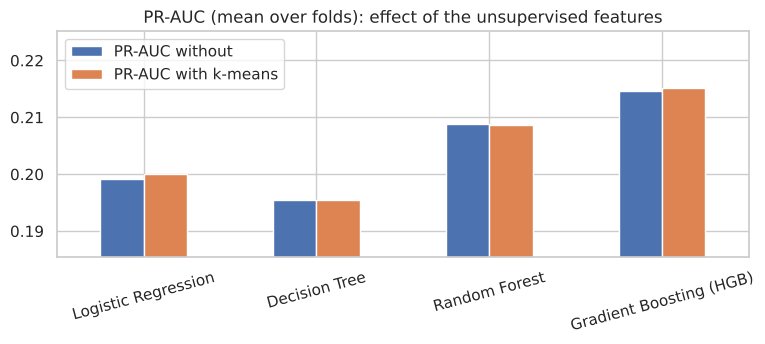

In [10]:
abl = pd.DataFrame({
    "PR-AUC without": {n: base_cv[(n, False)]["pr_auc"].mean() for n in names},
    "PR-AUC with k-means": {n: base_cv[(n, True)]["pr_auc"].mean() for n in names},
    "ROC-AUC without": {n: base_cv[(n, False)]["roc_auc"].mean() for n in names},
    "ROC-AUC with k-means": {n: base_cv[(n, True)]["roc_auc"].mean() for n in names},
})
abl["PR-AUC change"] = abl["PR-AUC with k-means"] - abl["PR-AUC without"]
display(abl.round(4))

mean_gain = abl["PR-AUC change"].mean()
USE_KM = bool(mean_gain > 0)
print(f"Average PR-AUC change across models: {mean_gain:+.4f}  ->  use k-means features for tuning: {USE_KM}")

ax = abl[["PR-AUC without", "PR-AUC with k-means"]].plot.bar(figsize=(8, 3.6), rot=15, color=["#4C72B0", "#DD8452"])
ax.set_ylim(abl[["PR-AUC without", "PR-AUC with k-means"]].min().min() - .01, abl[["PR-AUC without", "PR-AUC with k-means"]].max().max() + .01)
ax.set_title("PR-AUC (mean over folds): effect of the unsupervised features"); plt.tight_layout(); plt.show()

**Finding: the unsupervised features added essentially nothing.** PR-AUC changed by +0.0008 (logistic regression), 0.0000 (tree), -0.0001 (forest) and +0.0005 (HGB), an average of +0.0003, which is tiny compared with the fold-to-fold standard deviation (about 0.007 to 0.010).
By the rule fixed in advance (keep if the average change is positive) the cluster features were carried into tuning, but the honest conclusion is that they have no practical predictive value here. A plausible reason is that the cluster distances are built from the same columns the models already see, so flexible models can learn that structure themselves.
(A stricter rule, such as requiring a gain larger than one standard deviation, would have rejected them. We kept the original rule rather than change it after seeing the result; the clusters remain useful as a descriptive tool, Section 4.2.)

## 6. Hyperparameter tuning (randomised search)
*Analogy:* hyperparameters are the dials on a machine (tree depth, learning rate...). Grid search tries every combination of dial settings; **randomised search** tries a fixed number of random combinations,
which finds good settings much faster when there are many dials (Bergstra & Bengio, 2012).

Setup: `RandomizedSearchCV`, scoring = **PR-AUC (average precision)**, patient-grouped folds, training data only, then the best setting is re-fitted on all training data.
Each search space is chosen to cover under-fitting (too simple) through over-fitting (too complex).

In [11]:
search_spec = {
    "Logistic Regression": (LogisticRegression(max_iter=2000),
                            {"C": loguniform(1e-3, 10), "class_weight": [None, "balanced"]}),
    "Decision Tree": (DecisionTreeClassifier(random_state=SEED),
                      {"max_depth": randint(3, 16), "min_samples_leaf": randint(5, 200), "class_weight": [None, "balanced"]}),
    "Random Forest": (RandomForestClassifier(n_estimators=RF_TREES, n_jobs=1, random_state=SEED),
                      {"max_depth": randint(6, 21), "min_samples_leaf": randint(5, 60), "max_features": ["sqrt", 0.2],
                       "class_weight": [None, "balanced_subsample"]}),
    "Gradient Boosting (HGB)": (HistGradientBoostingClassifier(random_state=SEED),
                                {"learning_rate": loguniform(0.02, 0.3), "max_leaf_nodes": randint(8, 64),
                                 "min_samples_leaf": randint(20, 200), "l2_regularization": loguniform(1e-3, 10),
                                 "class_weight": [None, "balanced"]}),
}
search_folds = list(StratifiedGroupKFold(n_splits=SEARCH_FOLDS, shuffle=True, random_state=SEED).split(X_train, y_train, groups_train))

searches = {}
print(f"Tuning with k-means features: {USE_KM}\n", flush=True)
for name, (clf, space) in search_spec.items():
    t0 = time.time()
    rs_ = RandomizedSearchCV(make_pipe(clf, USE_KM), {f"clf__{k}": v for k, v in space.items()}, n_iter=N_ITER[name],
                             scoring="average_precision", cv=search_folds, random_state=SEED, n_jobs=1,
                             refit=True, error_score="raise")
    rs_.fit(X_train, y_train)
    searches[name] = rs_
    print(f"{name:26s} {N_ITER[name]:>2} candidates x {SEARCH_FOLDS} folds | best search PR-AUC {rs_.best_score_:.4f} | {time.time() - t0:5.0f}s", flush=True)

best_params = pd.DataFrame({n: {k.replace("clf__", ""): (round(v, 4) if isinstance(v, float) else v)
                                for k, v in s.best_params_.items()} for n, s in searches.items()}).T
print("\nBest hyperparameters found:")
display(best_params)

Tuning with k-means features: True



Logistic Regression         6 candidates x 3 folds | best search PR-AUC 0.2011 |    81s


Decision Tree              10 candidates x 3 folds | best search PR-AUC 0.1923 |   111s


Random Forest               5 candidates x 3 folds | best search PR-AUC 0.2160 |   172s


Gradient Boosting (HGB)    10 candidates x 3 folds | best search PR-AUC 0.2161 |   192s



Best hyperparameters found:


,C,class_weight,max_depth,min_samples_leaf,max_features,l2_regularization,learning_rate,max_leaf_nodes
Logistic Regression,3.7011,NaN,NaN,NaN,NaN,NaN,NaN,NaN
Decision Tree,NaN,balanced,7,197,NaN,NaN,NaN,NaN
Random Forest,NaN,NaN,14.0,9.0,0.2,NaN,NaN,NaN
Gradient Boosting (HGB),NaN,NaN,NaN,32.0,NaN,0.2154,0.0506,52.0


Re-evaluating tuned models on the 5 comparison folds:


   Logistic Regression                    done in     9s


   Decision Tree                          done in     8s


   Random Forest                          done in    51s


   Gradient Boosting (HGB)                done in    22s


,default PR-AUC,tuned PR-AUC,tuned PR-AUC std,default ROC-AUC,tuned ROC-AUC,PR-AUC gain
Logistic Regression,0.2000,0.2014,0.0074,0.6606,0.6599,0.0014
Decision Tree,0.1954,0.1950,0.0067,0.6489,0.6498,-0.0004
Random Forest,0.2086,0.2185,0.0082,0.6640,0.6650,0.0099
Gradient Boosting (HGB),0.2152,0.2202,0.0114,0.6642,0.6647,0.0051


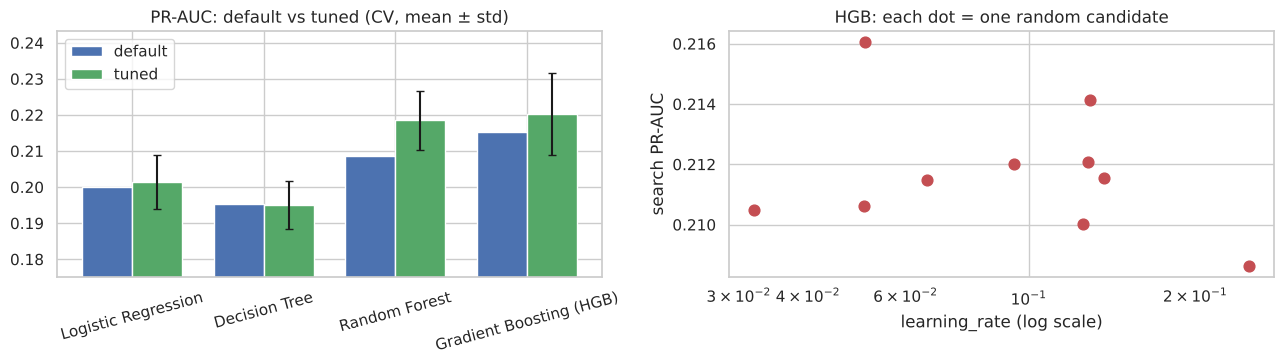

In [12]:
# Fair before/after comparison: re-evaluate the TUNED pipelines on the SAME 5 folds used for the defaults
tuned = {n: s.best_estimator_ for n, s in searches.items()}
tuned_cv, tuned_oof = {}, {}
print(f"Re-evaluating tuned models on the {CV_FOLDS} comparison folds:", flush=True)
for name in names:
    tuned_oof[name], tuned_cv[name] = cv_eval(tuned[name], name)

cmp = pd.DataFrame({
    "default PR-AUC": {n: base_cv[(n, USE_KM)]["pr_auc"].mean() for n in names},
    "tuned PR-AUC": {n: tuned_cv[n]["pr_auc"].mean() for n in names},
    "tuned PR-AUC std": {n: tuned_cv[n]["pr_auc"].std() for n in names},
    "default ROC-AUC": {n: base_cv[(n, USE_KM)]["roc_auc"].mean() for n in names},
    "tuned ROC-AUC": {n: tuned_cv[n]["roc_auc"].mean() for n in names},
})
cmp["PR-AUC gain"] = cmp["tuned PR-AUC"] - cmp["default PR-AUC"]
display(cmp.round(4))

fig, ax = plt.subplots(1, 2, figsize=(13, 3.8))
x = np.arange(len(names)); w = .38
ax[0].bar(x - w / 2, cmp["default PR-AUC"], w, label="default", color="#4C72B0")
ax[0].bar(x + w / 2, cmp["tuned PR-AUC"], w, yerr=cmp["tuned PR-AUC std"], label="tuned", color="#55A868", capsize=3)
ax[0].set_xticks(x); ax[0].set_xticklabels(names, rotation=15); ax[0].set_ylim(cmp[["default PR-AUC", "tuned PR-AUC"]].min().min() - .02, None)
ax[0].set_title("PR-AUC: default vs tuned (CV, mean ± std)"); ax[0].legend()

hgb = pd.DataFrame(searches["Gradient Boosting (HGB)"].cv_results_)
ax[1].scatter(hgb["param_clf__learning_rate"].astype(float), hgb["mean_test_score"], s=60, color="#C44E52")
ax[1].set_xscale("log"); ax[1].set_xlabel("learning_rate (log scale)"); ax[1].set_ylabel("search PR-AUC")
ax[1].set_title("HGB: each dot = one random candidate")
plt.tight_layout(); plt.show()

**Findings.**
* **Tuning gains were small.** On the same five folds, PR-AUC moved from 0.2000 to 0.2014 (logistic regression), 0.1954 to 0.1950 (tree), 0.2086 to 0.2185 (forest) and 0.2152 to 0.2202 (HGB). Only the forest's gain (+0.0099) is about one fold-standard-deviation (0.008); the others are within noise. The flat results suggest the ceiling is set by the information in the data, not by the settings.
* **Search size.** Each search tried only 5 to 10 candidates over 3 folds because of compute limits, so a larger search could find slightly better settings.
* **What the search chose.** Logistic regression, forest and HGB all preferred *no* class weighting (they rely on the decision threshold instead, Section 7). The tree stayed shallow (depth 7, at least 197 rows per leaf). HGB chose a low learning rate (0.051) with up to 52 leaves per tree and L2 regularisation of 0.215, a conservative, regularised model.
* The decision tree's tuned setting scored marginally below its default on the comparison folds (0.1950 vs 0.1954): random search with 10 candidates is not guaranteed to beat a good default.

## 7. Choosing the decision threshold (from training data only)
A model outputs a probability. Turning it into "flag / don't flag" needs a **threshold**. 0.5 is rarely right for a rare class, so we pick the threshold that maximises F1 on the
**out-of-fold** training predictions (predictions made for patients the model had not been trained on). The test set plays no part in this choice.

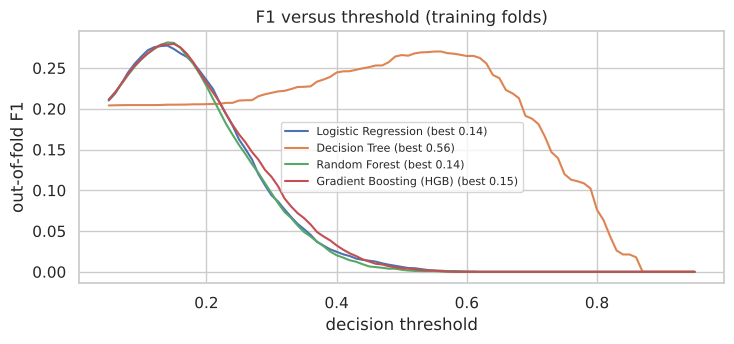

Chosen thresholds: {'Logistic Regression': 0.14, 'Decision Tree': 0.56, 'Random Forest': 0.14, 'Gradient Boosting (HGB)': 0.15}


In [13]:
grid = np.round(np.arange(0.05, 0.96, 0.01), 2)
thr_star, f1_curves = {}, {}
for name in names:
    f1s = np.array([f1_score(y_train, (tuned_oof[name] >= t).astype(int), zero_division=0) for t in grid])
    f1_curves[name], thr_star[name] = f1s, float(grid[f1s.argmax()])

plt.figure(figsize=(7.5, 3.6))
for name in names:
    plt.plot(grid, f1_curves[name], label=f"{name} (best {thr_star[name]:.2f})")
plt.xlabel("decision threshold"); plt.ylabel("out-of-fold F1"); plt.title("F1 versus threshold (training folds)"); plt.legend(fontsize=8)
plt.tight_layout(); plt.show()

print("Chosen thresholds:", {n: thr_star[n] for n in names})

## 8. Final evaluation on the untouched test set
The test set (about 20 % of patients, never used for fitting, cross-validation, tuning or the threshold) is used **once** here.
The model to highlight is chosen by its **cross-validated PR-AUC on the training data**, not by test results.

In [14]:
p_test = {n: tuned[n].predict_proba(X_test)[:, 1] for n in names}
dummy_test = DummyClassifier(strategy="prior").fit(X_train, y_train).predict_proba(X_test)[:, 1]

rows = {"Dummy baseline (thr 0.50)": metrics_at(y_test, dummy_test, 0.5)}
for n in names:
    rows[f"{n} (thr 0.50)"] = metrics_at(y_test, p_test[n], 0.5)
    rows[f"{n} (thr {thr_star[n]:.2f})"] = metrics_at(y_test, p_test[n], thr_star[n])
test_tbl = pd.DataFrame(rows).T
display(test_tbl.round(3))

best_name = cmp["tuned PR-AUC"].idxmax()          # chosen on TRAINING cross-validation only
print("Model chosen by cross-validated PR-AUC:", best_name)

,accuracy,balanced_acc,precision,recall,f1,roc_auc,pr_auc,rmse_prob
Dummy baseline (thr 0.50),0.886,0.500,0.000,0.000,0.000,0.500,0.114,0.317
Logistic Regression (thr 0.50),0.886,0.502,0.421,0.004,0.009,0.666,0.216,0.310
Logistic Regression (thr 0.14),0.743,0.606,0.203,0.429,0.275,0.666,0.216,0.310
Decision Tree (thr 0.50),0.701,0.612,0.189,0.496,0.274,0.654,0.217,0.476
Decision Tree (thr 0.56),0.723,0.608,0.195,0.459,0.273,0.654,0.217,0.476
Random Forest (thr 0.50),0.886,0.500,0.000,0.000,0.000,0.675,0.233,0.309
Random Forest (thr 0.14),0.740,0.618,0.208,0.459,0.287,0.675,0.233,0.309
Gradient Boosting (HGB) (thr 0.50),0.886,0.501,0.667,0.001,0.002,0.672,0.239,0.309
Gradient Boosting (HGB) (thr 0.15),0.767,0.612,0.219,0.410,0.286,0.672,0.239,0.309


Model chosen by cross-validated PR-AUC: Gradient Boosting (HGB)


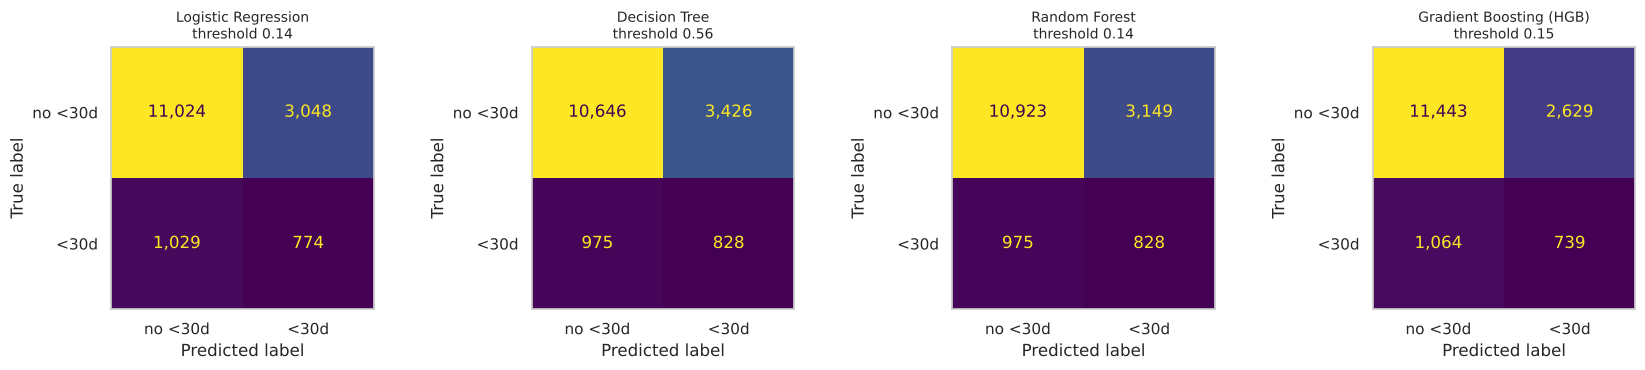

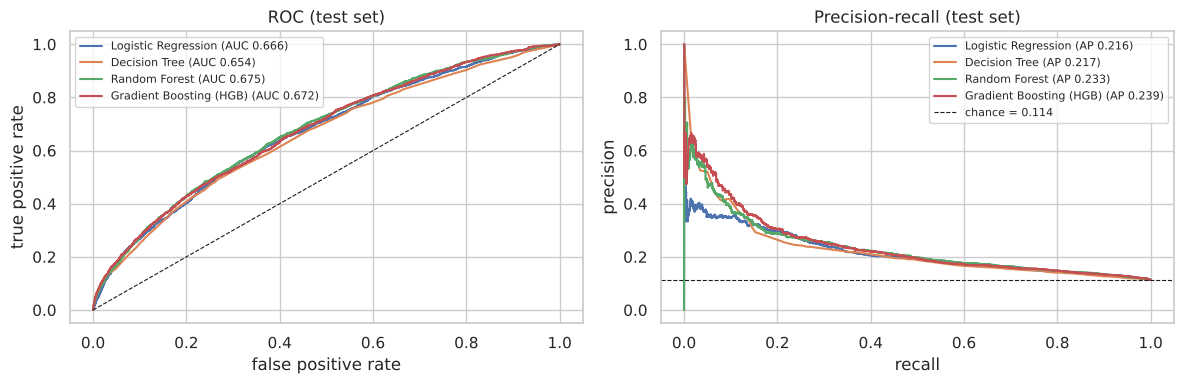

In [15]:
# Confusion matrices at each model's tuned threshold
fig, axes = plt.subplots(1, 4, figsize=(17, 3.8))
for ax, n in zip(axes, names):
    pred = (p_test[n] >= thr_star[n]).astype(int)
    ConfusionMatrixDisplay.from_predictions(y_test, pred, ax=ax, colorbar=False, display_labels=["no <30d", "<30d"], values_format=",d")
    ax.set_title(f"{n}\nthreshold {thr_star[n]:.2f}", fontsize=10); ax.grid(False)
plt.tight_layout(); plt.show()

# ROC and precision-recall curves
fig, ax = plt.subplots(1, 2, figsize=(12, 4))
for n in names:
    fpr, tpr, _ = roc_curve(y_test, p_test[n]); ax[0].plot(fpr, tpr, label=f"{n} (AUC {roc_auc_score(y_test, p_test[n]):.3f})")
    pr, rc, _ = precision_recall_curve(y_test, p_test[n]); ax[1].plot(rc, pr, label=f"{n} (AP {average_precision_score(y_test, p_test[n]):.3f})")
ax[0].plot([0, 1], [0, 1], "k--", lw=.8); ax[0].set_xlabel("false positive rate"); ax[0].set_ylabel("true positive rate"); ax[0].set_title("ROC (test set)")
ax[1].axhline(y_test.mean(), color="k", ls="--", lw=.8, label=f"chance = {y_test.mean():.3f}")
ax[1].set_xlabel("recall"); ax[1].set_ylabel("precision"); ax[1].set_title("Precision-recall (test set)")
for a in ax: a.legend(fontsize=8)
plt.tight_layout(); plt.show()

### 8.1 Is the difference between models real? Patient-level bootstrap
One test set gives one number per model, and small gaps can be luck. We resample **patients** (not rows) with replacement many times and recompute PR-AUC on each resample.
If the intervals overlap heavily, the models cannot be separated with confidence.

In [16]:
y_te = y_test.values
g_list = list(pd.Series(np.arange(len(y_te))).groupby(groups_test.values).apply(lambda s: s.values).values)
rb = np.random.RandomState(SEED)
boot = {n: [] for n in names}
for _ in range(N_BOOT):
    pick = rb.randint(0, len(g_list), size=len(g_list))
    ix = np.concatenate([g_list[i] for i in pick])
    for n in names:
        boot[n].append(average_precision_score(y_te[ix], p_test[n][ix]))
boot = {n: np.array(v) for n, v in boot.items()}

ci = pd.DataFrame({n: {"PR-AUC (test)": average_precision_score(y_te, p_test[n]),
                       "95% CI low": np.percentile(boot[n], 2.5), "95% CI high": np.percentile(boot[n], 97.5)} for n in names}).T
display(ci.round(4))

others = [n for n in names if n != best_name]
print(f"Paired bootstrap difference in PR-AUC: {best_name} minus each other model")
for n in others:
    d = boot[best_name] - boot[n]
    print(f"  vs {n:26s} mean diff {d.mean():+.4f} | 95% CI [{np.percentile(d, 2.5):+.4f}, {np.percentile(d, 97.5):+.4f}] | "
          f"{'clearly better' if np.percentile(d, 2.5) > 0 else 'not clearly different'}")

,PR-AUC (test),95% CI low,95% CI high
Logistic Regression,0.2158,0.1915,0.2350
Decision Tree,0.2168,0.1892,0.2449
Random Forest,0.2330,0.2045,0.2576
Gradient Boosting (HGB),0.2388,0.2070,0.2652


Paired bootstrap difference in PR-AUC: Gradient Boosting (HGB) minus each other model
  vs Logistic Regression        mean diff +0.0222 | 95% CI [+0.0065, +0.0379] | clearly better
  vs Decision Tree              mean diff +0.0219 | 95% CI [+0.0119, +0.0327] | clearly better
  vs Random Forest              mean diff +0.0053 | 95% CI [-0.0018, +0.0123] | not clearly different


**Findings (test set, 15,875 encounters from 11,148 patients never used before).**
* **Best model: gradient boosting (HGB)**, chosen by cross-validated PR-AUC on the training data (0.2202, versus 0.2185 for the forest, a difference within noise). At its tuned threshold of 0.15 it reaches test **PR-AUC 0.239, ROC-AUC 0.672, recall 0.410, precision 0.219, F1 0.286, accuracy 0.767**. The test PR-AUC (about 2.1 times the 0.114 chance level) sits inside the cross-validation range, so there is no sign of over-fitting to the validation folds.
* **In plain terms:** of 100 patients the model flags, about 22 really return within 30 days (versus 11 in the whole population, a 1.9 times enrichment), and it catches about 41 % of all early readmissions. It is a screening aid with many false alarms, not a reliable individual predictor.
* **Threshold matters.** At the default 0.5, the three unweighted models flag almost nobody (HGB recall 0.001), so their accuracy of 0.886 is identical to the dummy's. The thresholds chosen on training data (about 0.14 to 0.15) turn the same probabilities into useful flags.
* **Are the models really different?** HGB's PR-AUC advantage over logistic regression (+0.022, 95 % CI +0.007 to +0.038) and over the tree (+0.022, CI +0.012 to +0.033) is clearly above zero. Against the random forest (+0.005, CI -0.002 to +0.012) it is **not** clearly different. Logistic regression and the tree are statistically hard to tell apart from each other on this evidence.
* **Probability RMSE** is about 0.309 to 0.310 for the unweighted models, only slightly better than the dummy's 0.317: probability errors are dominated by the unpredictability of the outcome. The class-weighted tree scores 0.476 because class weights distort its probabilities; RMSE is not a ranking metric and should be read alongside PR-AUC.

## 9. What drives the predictions? (permutation importance)
*Analogy:* take one column, shuffle its values so they no longer match the right patients, and watch how much worse the model gets. A big drop means the model relied on that column.
Computed on a random sample of test rows for the chosen model, in terms of the original (un-encoded) columns.

Permutation importance for Gradient Boosting (HGB) (7s):


,feature,drop_in_PR_AUC,std
13,number_inpatient,0.0633,0.0094
3,discharge_disposition_id,0.0489,0.0055
25,insulin,0.0054,0.0032
31,diag_2_group,0.0052,0.0005
30,diag_1_group,0.0049,0.0012
4,admission_source_id,0.0047,0.0014
2,admission_type_id,0.0039,0.0027
5,time_in_hospital,0.0035,0.0008
11,number_outpatient,0.0033,0.0015
12,number_emergency,0.0033,0.0012


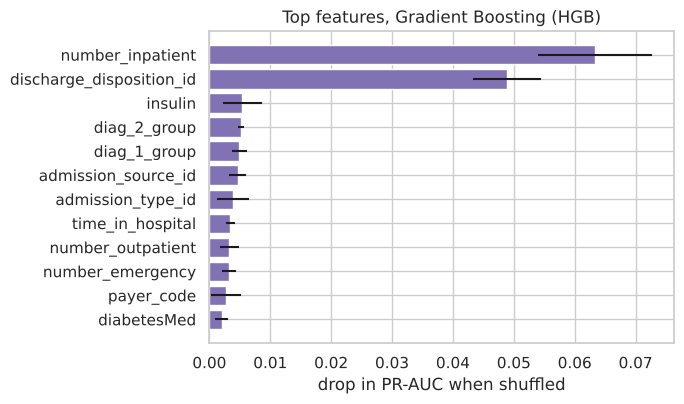

In [17]:
rp = np.random.RandomState(SEED)
pi_ix = rp.choice(len(X_test), size=min(PERM_ROWS, len(X_test)), replace=False)
t0 = time.time()
pi = permutation_importance(tuned[best_name], X_test.iloc[pi_ix], y_test.iloc[pi_ix], scoring="average_precision",
                            n_repeats=PERM_REPEATS, random_state=SEED, n_jobs=1)
imp = pd.DataFrame({"feature": X_test.columns, "drop_in_PR_AUC": pi.importances_mean, "std": pi.importances_std}) \
        .sort_values("drop_in_PR_AUC", ascending=False)
print(f"Permutation importance for {best_name} ({time.time() - t0:.0f}s):")
display(imp.head(12).round(4))

top = imp.head(12).iloc[::-1]
plt.figure(figsize=(7, 4.2)); plt.barh(top["feature"], top["drop_in_PR_AUC"], xerr=top["std"], color="#8172B3")
plt.xlabel("drop in PR-AUC when shuffled"); plt.title(f"Top features, {best_name}"); plt.tight_layout(); plt.show()

**Findings.** Two features dominate: **earlier inpatient visits** (`number_inpatient`, PR-AUC drop of 0.063) and **where the patient was discharged to** (`discharge_disposition_id`, drop of 0.049). Every other feature contributes 0.005 or less, led by insulin use, the diagnosis groups and admission source.
This agrees with the clusters (the highest-risk cluster had the most earlier inpatient visits) and with the exploratory analysis in Milestone 1. **Caution:** permutation importance shows what the model relies on, not what causes readmission, and correlated features can share credit. It was computed on 4,000 test rows with 5 repeats.

## 10. Save results for Milestone 3 and summarise

In [18]:
os.makedirs("m2_outputs", exist_ok=True)
tbl.to_csv("m2_outputs/cv_default_models.csv")
abl.to_csv("m2_outputs/ablation_kmeans.csv")
cmp.to_csv("m2_outputs/tuned_vs_default_cv.csv")
test_tbl.to_csv("m2_outputs/test_metrics.csv")
best_params.to_csv("m2_outputs/best_hyperparameters.csv")
joblib.dump(tuned[best_name], "m2_outputs/best_pipeline.joblib")

summary = {"student_id": STUDENT_ID, "seed": SEED, "quick_run": QUICK_RUN,
           "train_rows": len(X_train), "test_rows": len(X_test),
           "cv_folds": CV_FOLDS, "k_means_k": K_CLUSTERS, "kmeans_features_used": USE_KM,
           "chosen_model": best_name, "chosen_threshold": thr_star[best_name],
           "test_pr_auc": round(float(test_tbl.loc[f"{best_name} (thr {thr_star[best_name]:.2f})", "pr_auc"]), 4),
           "test_roc_auc": round(float(test_tbl.loc[f"{best_name} (thr {thr_star[best_name]:.2f})", "roc_auc"]), 4),
           "test_recall": round(float(test_tbl.loc[f"{best_name} (thr {thr_star[best_name]:.2f})", "recall"]), 4),
           "test_precision": round(float(test_tbl.loc[f"{best_name} (thr {thr_star[best_name]:.2f})", "precision"]), 4),
           "test_f1": round(float(test_tbl.loc[f"{best_name} (thr {thr_star[best_name]:.2f})", "f1"]), 4)}
for k, v in summary.items():
    print(f"{k:22s}: {v}")

student_id            : SH2301468
seed                  : 2301468
quick_run             : False
train_rows            : 63490
test_rows             : 15875
cv_folds              : 5
k_means_k             : 3
kmeans_features_used  : True
chosen_model          : Gradient Boosting (HGB)
chosen_threshold      : 0.15
test_pr_auc           : 0.2388
test_roc_auc          : 0.6725
test_recall           : 0.4099
test_precision        : 0.2194
test_f1               : 0.2858


## 11. Conclusions, limitations and links to Milestone 3
**Conclusions**
* All four supervised models clearly beat the do-nothing baseline (PR-AUC 0.195 to 0.239 against 0.114), but the best reaches only ROC-AUC 0.67: 30-day readmission is hard to predict from hospital-record data alone.
* Gradient boosting was best, and clearly better than logistic regression and a single tree, but not clearly better than a random forest.
* Hyperparameter tuning improved results only slightly; the k-means features added no measurable value, which is a result worth reporting, not hiding.
* Decision-threshold choice mattered far more than most hyperparameters for the F1 and recall that a user would experience.

**Limitations**
* Small random searches (5 to 10 candidates), one test split and one random seed for the model fits.
* Both the clustering and k-means features relied on Euclidean distance over mixed data.
* No calibration step and no fairness check across race, gender or age groups yet.
* Data are from 1999 to 2008 at US hospitals; performance on current data or other countries is unknown.

**For Milestone 3.** The saved files in `m2_outputs/` (cross-validation tables, tuned hyper-parameters, test metrics and the best pipeline) are the "tuned student model" to compare against an AI-generated baseline on exactly the same personalised subsample, split and metrics.